# Ship detection — Dnipro-Bug estuary, Mykolaiv (September 2023)

Runs the `ship_detection` UDP (Sentinel-2 NDWI water mask combined with bright Sentinel-1 VV/VH backscatter over water) on CDSE over the port of Mykolaiv and the Southern Bug river, then plots the result.

Scenes picked up by the window (openEO end dates are exclusive; the UDP keeps the first scene per sensor):

| Window | Sentinel-1 GRD | Sentinel-2 L1C |
|---|---|---|
| 2023-09-03 → 2023-09-07 | 2023-09-05 (descending, full bbox) | 2023-09-04 (0–4% cloud) |

In [1]:
from pathlib import Path

import openeo

connection = openeo.connect("https://openeo.dataspace.copernicus.eu/").authenticate_oidc()

Authenticated using refresh token.


In [2]:
# Bounding box and temporal extent
shape = {"west": 31.745689, "south": 46.600381, "east": 32.126161, "north": 47.020555}
start_date, end_date = ["2023-09-03", "2023-09-07"]

public_url = "https://raw.githubusercontent.com/ESA-APEx/apex_algorithms/469727a7ddd98c74a0d61e8966b55bbd2f6630ad/algorithm_catalog/developmentseed/ship_detection/openeo_udp/ship_detection.json"

# The process id must match the "id" in the UDP JSON at public_url.
process_id = "ship_detection"

output = Path("ship_detection_mykolaiv.tiff")

In [3]:
ships_mykolaiv = connection.datacube_from_process(
    process_id,
    namespace=public_url,
    time=[start_date, end_date],
    bounding_box=shape,
)

## Ship detection

In [4]:
job = ships_mykolaiv.create_job(
    title=f"Ship detection for {start_date} to {end_date}",
    out_format="GTiff",
)
job.start_and_wait()

0:00:00 Job 'j-2610271759304ebbac339b3d75f5f6e4': send 'start'
0:00:02 Job 'j-2610271759304ebbac339b3d75f5f6e4': created (progress 0%)
0:00:07 Job 'j-2610271759304ebbac339b3d75f5f6e4': queued (progress 0%)
0:00:13 Job 'j-2610271759304ebbac339b3d75f5f6e4': queued (progress 0%)
0:00:21 Job 'j-2610271759304ebbac339b3d75f5f6e4': queued (progress 0%)
0:00:31 Job 'j-2610271759304ebbac339b3d75f5f6e4': queued (progress 0%)
0:00:44 Job 'j-2610271759304ebbac339b3d75f5f6e4': running (progress N/A)
0:00:59 Job 'j-2610271759304ebbac339b3d75f5f6e4': running (progress N/A)
0:01:18 Job 'j-2610271759304ebbac339b3d75f5f6e4': running (progress N/A)
0:01:42 Job 'j-2610271759304ebbac339b3d75f5f6e4': running (progress N/A)
0:02:12 Job 'j-2610271759304ebbac339b3d75f5f6e4': running (progress N/A)
0:02:50 Job 'j-2610271759304ebbac339b3d75f5f6e4': running (progress N/A)
0:03:37 Job 'j-2610271759304ebbac339b3d75f5f6e4': running (progress N/A)
0:04:35 Job 'j-2610271759304ebbac339b3d75f5f6e4': finished (progress 1

<BatchJob job_id='j-2610271759304ebbac339b3d75f5f6e4'>

In [5]:
# The result is a single GeoTIFF (~3 MB). If the download breaks, rerun only
# this cell; the job does not need to be resubmitted.
job.get_results().download_file(output)

PosixPath('ship_detection_mykolaiv.tiff')

## Detected ships

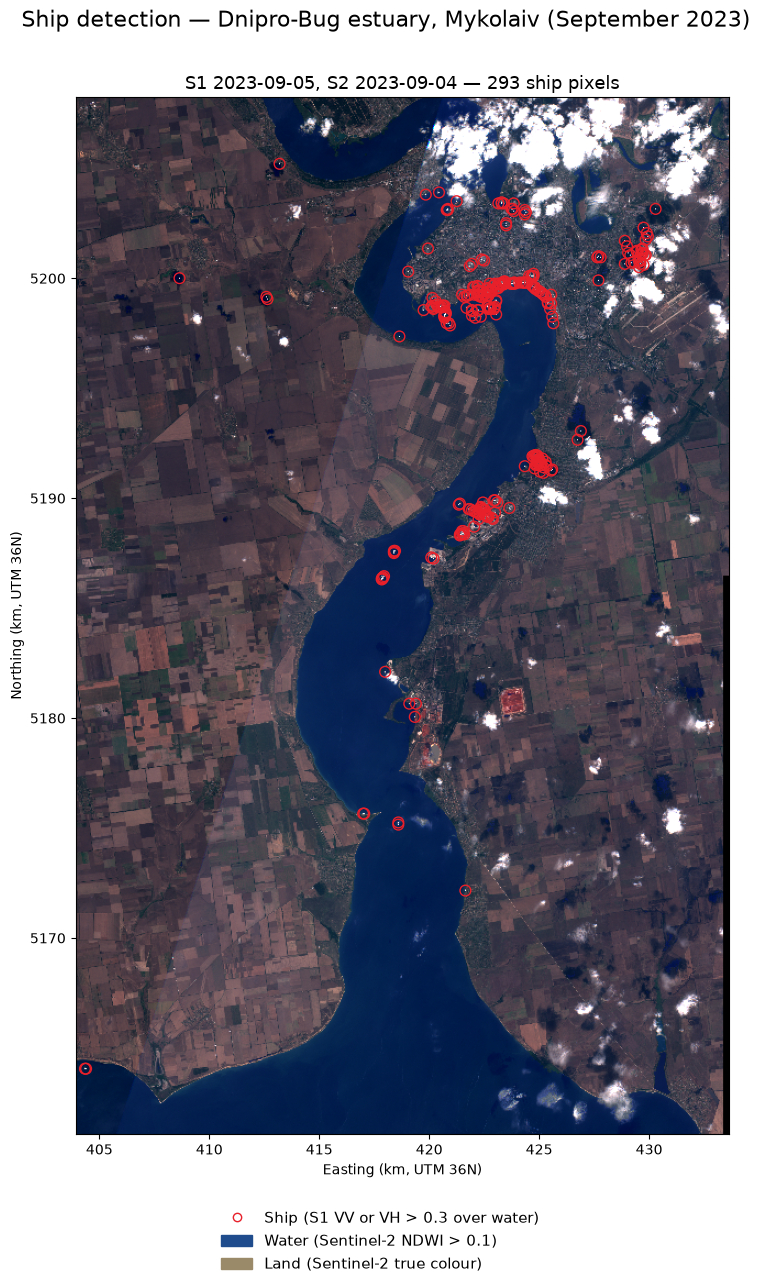

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import rasterio
from matplotlib.lines import Line2D
from matplotlib.patches import Patch


def read_rgb(path):
    """Read a 3-band ship_detection GeoTIFF as an (H, W, 3) 0-1 array plus its extent in km."""
    with rasterio.open(path) as src:
        data = src.read()
        b = src.bounds
    # The UDP output is already display-scaled; only clip to 0-1.
    rgb = np.clip(np.nan_to_num(np.moveaxis(data, 0, -1)), 0, 1)
    extent = [b.left / 1000, b.right / 1000, b.bottom / 1000, b.top / 1000]
    return rgb, extent, data


rgb, extent, data = read_rgb(output)

# The UDP paints ship pixels pure white (1, 1, 1). Ring them so the 50 m pixels
# stay visible at full-scene scale.
rows, cols = np.nonzero(np.all(data == 1.0, axis=0))
height, width = rgb.shape[:2]
x = extent[0] + (cols + 0.5) / width * (extent[1] - extent[0])
y = extent[3] - (rows + 0.5) / height * (extent[3] - extent[2])

fig, ax = plt.subplots(figsize=(9, 13))
ax.imshow(rgb, extent=extent)
ax.scatter(x, y, s=60, facecolors="none", edgecolors="#e8202a", linewidths=1)
ax.set_title(f"S1 2023-09-05, S2 2023-09-04 — {len(rows)} ship pixels", fontsize=13)
ax.set_xlabel("Easting (km, UTM 36N)")
ax.set_ylabel("Northing (km, UTM 36N)")

fig.legend(
    handles=[
        Line2D([], [], marker="o", linestyle="none", markerfacecolor="none",
               markeredgecolor="#e8202a", label="Ship (S1 VV or VH > 0.3 over water)"),
        Patch(color="#1e4c8c", label="Water (Sentinel-2 NDWI > 0.1)"),
        Patch(color="#9a8a6a", label="Land (Sentinel-2 true colour)"),
    ],
    loc="lower center",
    ncol=1,
    frameon=False,
    fontsize=11,
)
fig.suptitle("Ship detection — Dnipro-Bug estuary, Mykolaiv (September 2023)", fontsize=16)
fig.tight_layout(rect=(0, 0.07, 1, 0.97))
fig.savefig("ship_detection_mykolaiv.png", dpi=200)
plt.show()